In [1]:
# Import data manipulation libraries
import pandas as pd
import numpy as np



In [2]:
# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
# Import preprocessing tools
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer


In [7]:
# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [8]:

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [9]:



# Import model-saving tool
import joblib

# Set visualization style
sns.set_theme(style="whitegrid", palette="viridis")

In [31]:
# Load the dataset
df = pd.read_csv("diabetes_prediction_dataset.csv")

# Display the first five records
df.head()


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [13]:
# Display the number of rows and columns
print("\nDataset shape:", df.shape)



Dataset shape: (100000, 9)


In [14]:
# Display column names and data types
print("\nDataset information:")
df.info()




Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [32]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [16]:
# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())




Missing values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [17]:
# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())


Duplicate records: 3854


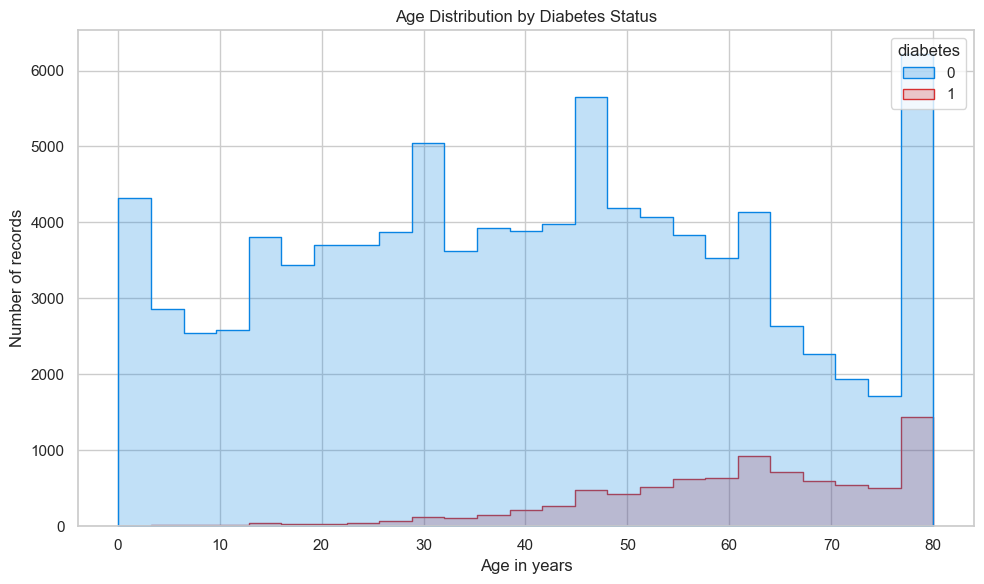

In [34]:
# AGE DISTRIBUTION

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="age",
    hue="diabetes",
    bins=25,
    element="step",
    palette={0: "#0984E3", 1: "#D63031"}
)

plt.title("Age Distribution by Diabetes Status")
plt.xlabel("Age in years")
plt.ylabel("Number of records")

plt.tight_layout()
plt.show()

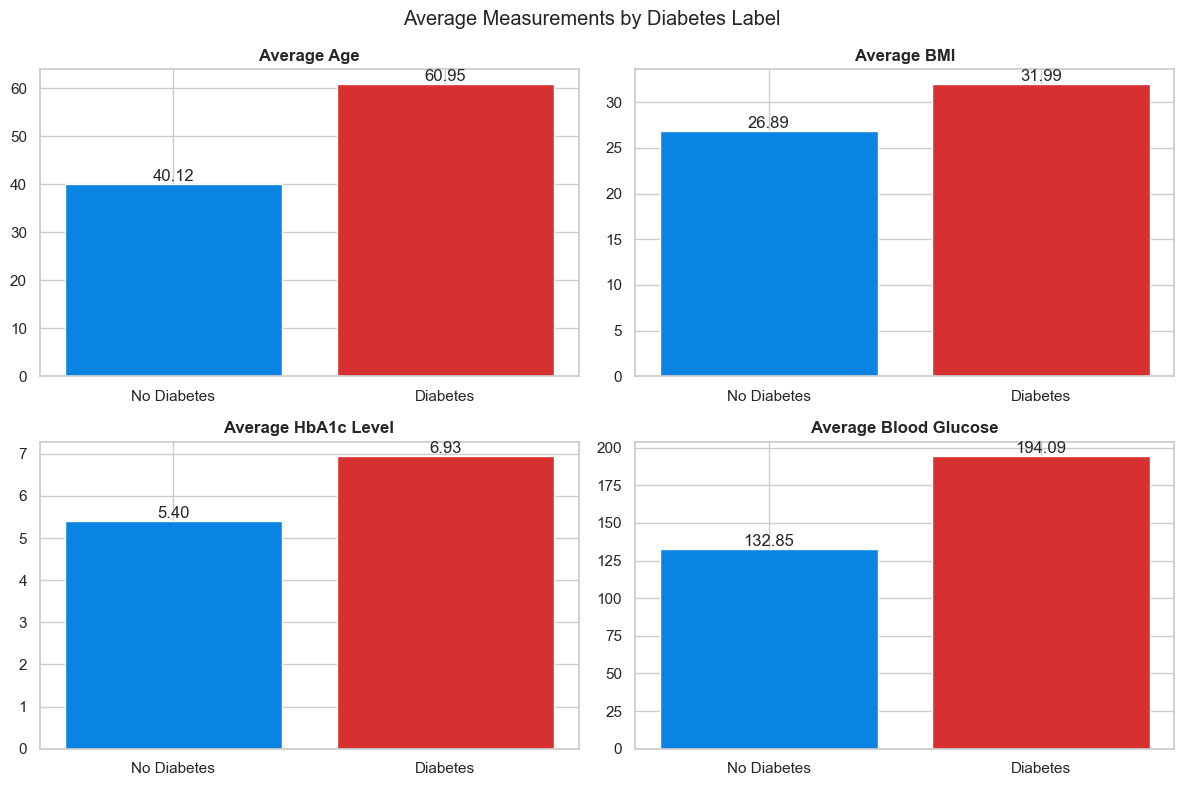

                age        bmi  HbA1c_level  blood_glucose_level
diabetes                                                        
0         40.115187  26.887163     5.396761           132.852470
1         60.946588  31.988382     6.934953           194.094706


In [35]:
# COMPARE AVERAGE HEALTH MEASUREMENTS

metrics = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]

means = df.groupby("diabetes")[metrics].mean()

titles = [
    "Average Age",
    "Average BMI",
    "Average HbA1c Level",
    "Average Blood Glucose"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col, title in zip(axes.flat, metrics, titles):

    values = [means.loc[0, col], means.loc[1, col]]

    bars = ax.bar(
        ["No Diabetes", "Diabetes"],
        values,
        color=["#0984E3", "#D63031"]
    )

    ax.set_title(title, fontweight="bold")

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.2f}",
            ha="center",
            va="bottom"
        )

fig.suptitle("Average Measurements by Diabetes Label")
plt.tight_layout()
plt.show()

print(means)

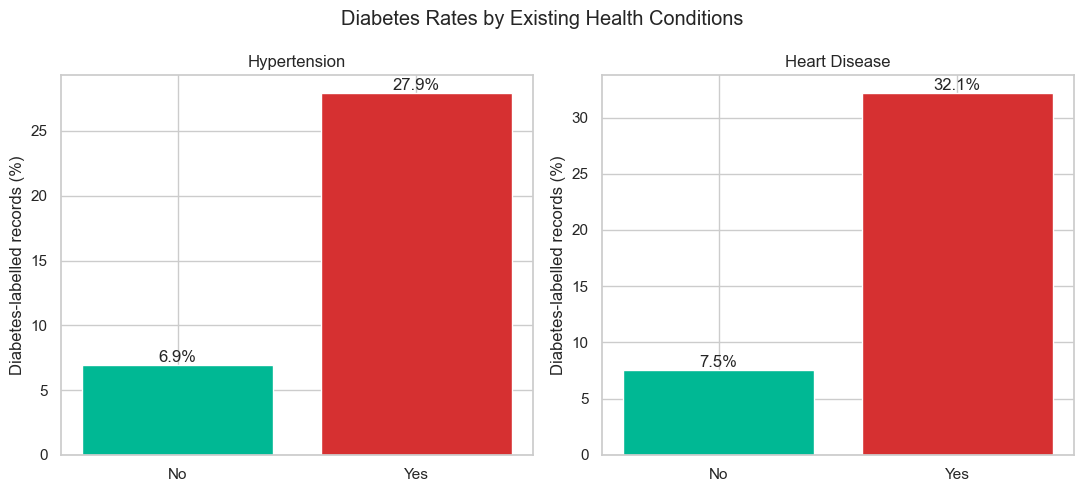

In [37]:
# EXISTING HEALTH CONDITIONS

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

conditions = ["hypertension", "heart_disease"]
titles = ["Hypertension", "Heart Disease"]

for ax, col, title in zip(axes, conditions, titles):

    rates = df.groupby(col)["diabetes"].mean().reindex([0, 1]) * 100

    bars = ax.bar(
        ["No", "Yes"],
        rates.values,
        color=["#00B894", "#D63031"]
    )

    ax.set_title(title)
    ax.set_ylabel("Diabetes-labelled records (%)")

    for bar, value in zip(bars, rates.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.1f}%",
            ha="center",
            va="bottom"
        )

fig.suptitle("Diabetes Rates by Existing Health Conditions")
plt.tight_layout()
plt.show()

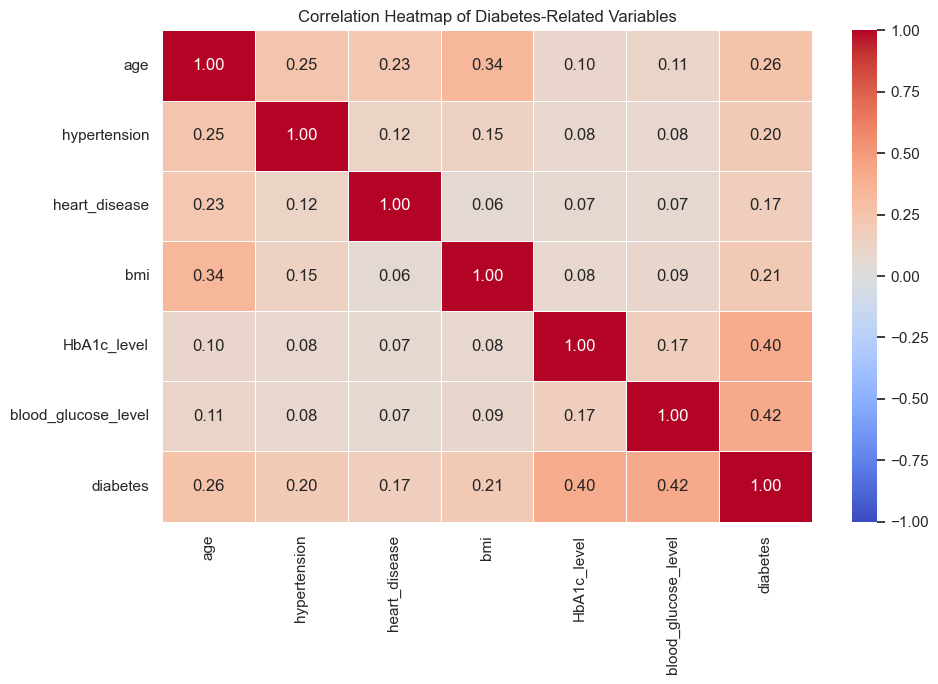

diabetes               1.000000
blood_glucose_level    0.419558
HbA1c_level            0.400660
age                    0.258008
bmi                    0.214357
hypertension           0.197823
heart_disease          0.171727
Name: diabetes, dtype: float64


In [38]:
# CORRELATION HEATMAP

numeric_cols = [
    "age", "hypertension", "heart_disease",
    "bmi", "HbA1c_level",
    "blood_glucose_level", "diabetes"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Diabetes-Related Variables")
plt.tight_layout()
plt.show()

print(corr["diabetes"].sort_values(ascending=False))

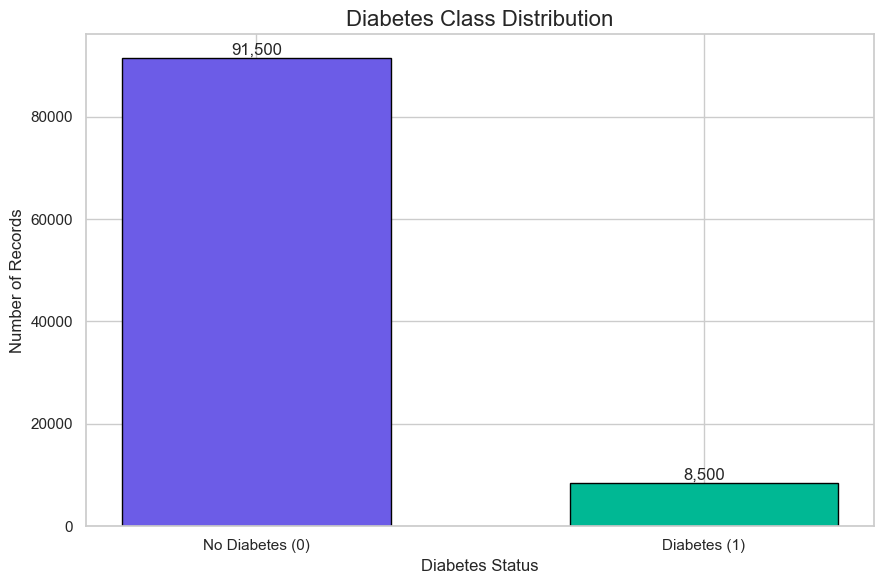

diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


In [18]:
# Count records in each diabetes category
diabetes_counts = df["diabetes"].value_counts().sort_index()

# Create a colorful bar chart
plt.figure(figsize=(9, 6))

bars = plt.bar(
    ["No Diabetes (0)", "Diabetes (1)"],
    diabetes_counts.values,
    color=["#6C5CE7", "#00B894"],
    edgecolor="black",
    width=0.6
)

# Add values above the bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=12
    )

plt.title("Diabetes Class Distribution", fontsize=16)
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Display percentages
print((df["diabetes"].value_counts(normalize=True) * 100).round(2))

In [19]:
# Check that the target column exists
if "diabetes" not in df.columns:
    raise ValueError("The dataset does not contain a 'diabetes' column.")

# Separate input features from the target
X = df.drop(columns=["diabetes"])
y = df["diabetes"]

# Confirm the feature columns
print("Input features:")
print(X.columns.tolist())

# Confirm the target values
print("\nTarget values:")
print(y.value_counts())

Input features:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']

Target values:
diabetes
0    91500
1     8500
Name: count, dtype: int64


In [20]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes of the datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (80000, 8)
Testing features: (20000, 8)

Training target distribution:
diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64

Testing target distribution:
diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64


In [21]:
# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

# Preprocessing for numerical columns
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully.")

Categorical features: ['gender', 'smoking_history']
Numerical features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']

Preprocessing pipeline created successfully.


In [22]:
# Create the Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Create the Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train Logistic Regression
print("Training Logistic Regression...")
logistic_model.fit(X_train, y_train)

# Train Random Forest
print("Training Random Forest...")
random_forest_model.fit(X_train, y_train)

print("\nBoth models have been trained successfully.")

Training Logistic Regression...
Training Random Forest...

Both models have been trained successfully.


In [23]:
# Define a function for model evaluation
def evaluate_model(model, X_test, y_test, model_name):

    # Generate predicted classes
    y_pred = model.predict(X_test)

    # Generate predicted probabilities for class 1
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    return results


# Evaluate both models
results = []

results.append(
    evaluate_model(
        logistic_model,
        X_test,
        y_test,
        "Logistic Regression"
    )
)

results.append(
    evaluate_model(
        random_forest_model,
        X_test,
        y_test,
        "Random Forest"
    )
)

# Display the comparison table
results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.8888     0.4266  0.8935    0.5775   0.9630
      Random Forest    0.9690     0.9300  0.6876    0.7907   0.9658


In [24]:
# Select the model you want to inspect
model = random_forest_model

# Generate predictions
y_pred = model.predict(X_test)

# Print the classification report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Diabetes (0)", "Diabetes (1)"],
        zero_division=0
    )
)

                 precision    recall  f1-score   support

No Diabetes (0)       0.97      1.00      0.98     18300
   Diabetes (1)       0.93      0.69      0.79      1700

       accuracy                           0.97     20000
      macro avg       0.95      0.84      0.89     20000
   weighted avg       0.97      0.97      0.97     20000



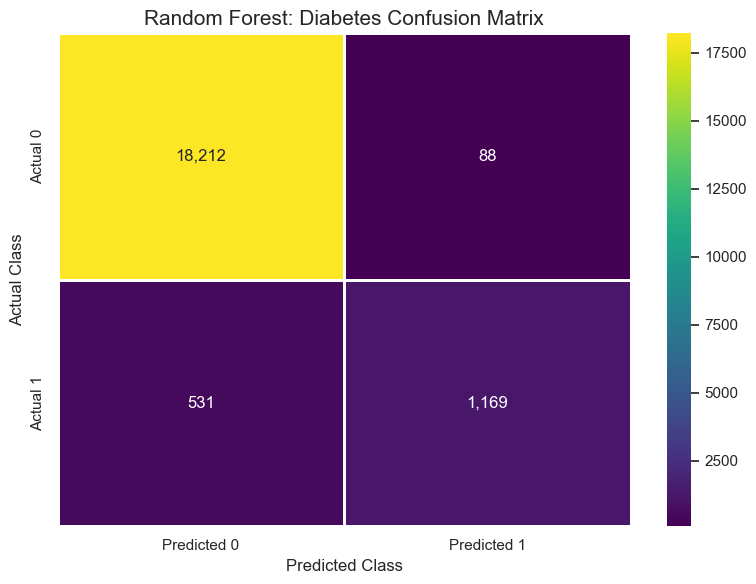

In [25]:
# Generate predictions using Random Forest
y_pred = random_forest_model.predict(X_test)

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="viridis",
    linewidths=1,
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.title("Random Forest: Diabetes Confusion Matrix", fontsize=15)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

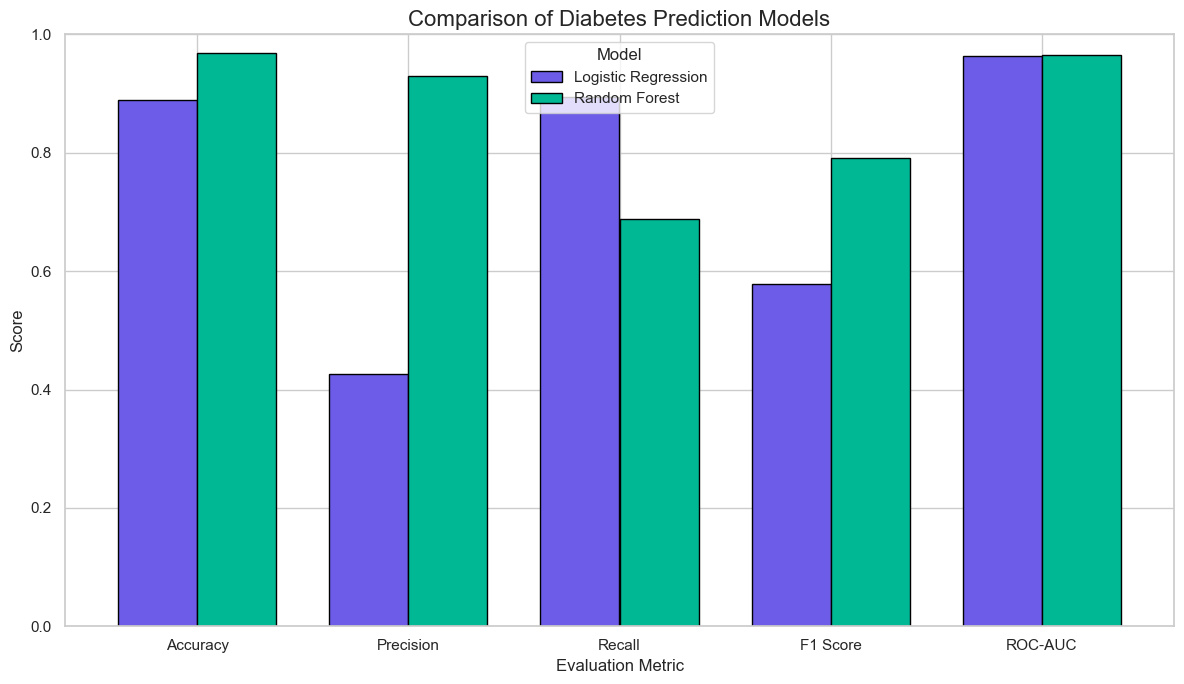

In [26]:
# Convert model results into a format suitable for plotting
metrics_df = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
]

# Plot the comparison
ax = metrics_df.T.plot(
    kind="bar",
    figsize=(12, 7),
    color=["#6C5CE7", "#00B894"],
    edgecolor="black",
    width=0.75
)

ax.set_title("Comparison of Diabetes Prediction Models", fontsize=16)
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

<Figure size 900x700 with 0 Axes>

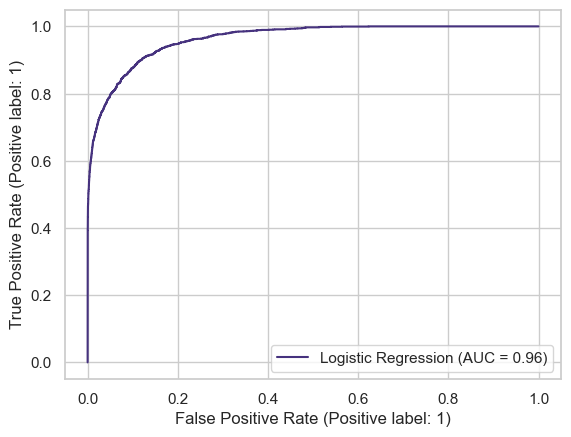

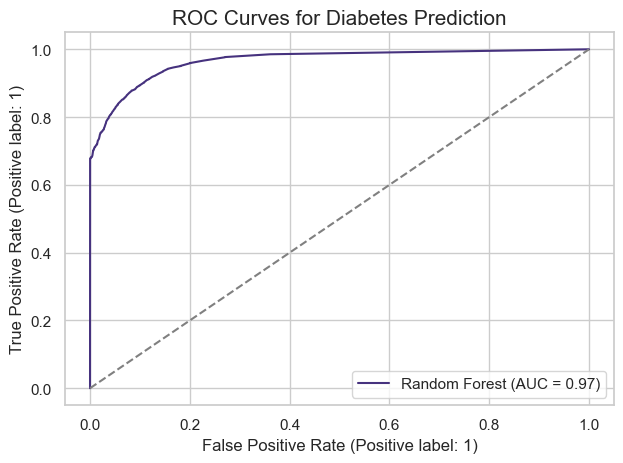

In [27]:
from sklearn.metrics import RocCurveDisplay

# Create the ROC curve
plt.figure(figsize=(9, 7))

RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    name="Logistic Regression"
)

RocCurveDisplay.from_estimator(
    random_forest_model,
    X_test,
    y_test,
    name="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random baseline"
)

plt.title("ROC Curves for Diabetes Prediction", fontsize=15)
plt.tight_layout()
plt.show()

In [28]:
# Create a sample record
new_person = pd.DataFrame([{
    "gender": "Female",
    "age": 45,
    "hypertension": 0,
    "heart_disease": 0,
    "smoking_history": "never",
    "bmi": 27.5,
    "HbA1c_level": 5.8,
    "blood_glucose_level": 130
}])

# Predict the diabetes class
predicted_class = random_forest_model.predict(new_person)[0]

# Predict the probability assigned to class 1
predicted_probability = (
    random_forest_model.predict_proba(new_person)[0, 1]
)

# Display the prediction
print("Predicted class:", predicted_class)

print(
    "Estimated probability of class 1:",
    f"{predicted_probability:.2%}"
)

if predicted_class == 1:
    print("The model predicts class 1.")
else:
    print("The model predicts class 0.")

Predicted class: 0
Estimated probability of class 1: 1.50%
The model predicts class 0.


                             Feature  Importance
4                   num__HbA1c_level    0.344567
5           num__blood_glucose_level    0.266937
0                           num__age    0.186058
3                           num__bmi    0.128937
1                  num__hypertension    0.025647
2                 num__heart_disease    0.013997
9       cat__smoking_history_No Info    0.012351
12       cat__smoking_history_former    0.005163
13        cat__smoking_history_never    0.003387
7                   cat__gender_Male    0.003019
6                 cat__gender_Female    0.002787
10      cat__smoking_history_current    0.002619
14  cat__smoking_history_not current    0.002506
11         cat__smoking_history_ever    0.002013
8                  cat__gender_Other    0.000011


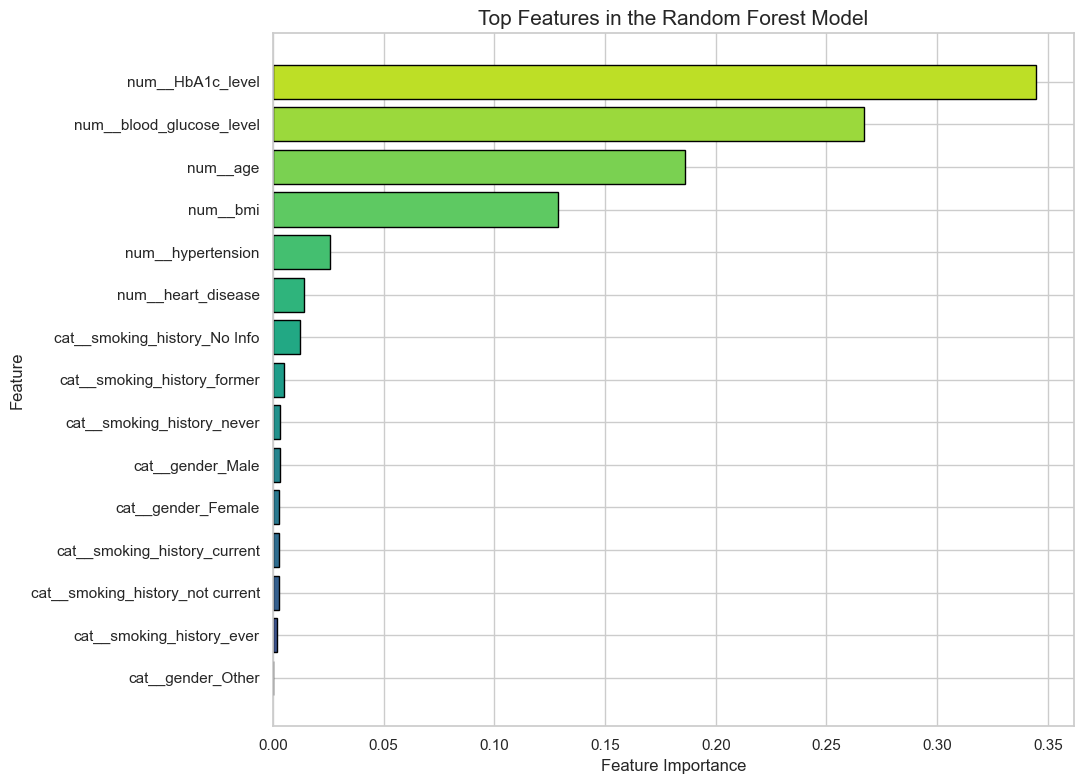

In [29]:
# Extract the trained Random Forest classifier
rf_classifier = random_forest_model.named_steps["classifier"]

# Extract the fitted preprocessing pipeline
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]

# Obtain transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract feature importance scores
importance = rf_classifier.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

# Display the top 15 features
print(importance_df.head(15))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    color=plt.cm.viridis(
        np.linspace(0.2, 0.9, len(top_features))
    ),
    edgecolor="black"
)

plt.title("Top Features in the Random Forest Model", fontsize=15)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Conclusion

The analysis of the diabetes prediction dataset demonstrated how machine learning can identify patterns associated with diabetes. The findings showed that age, BMI, HbA1c levels, and blood glucose levels differed between individuals labelled as having diabetes and those labelled as not having diabetes. Two models were evaluated: Logistic Regression achieved an accuracy of **88.88%**, while Random Forest achieved **96.91%**. However, for **diabetes screening, Logistic Regression is the more suitable candidate based on the reported recall scores**: 89.35%, compared with 68.76% for Random Forest. This means Logistic Regression identified a larger proportion of actual diabetes-positive cases in the test dataset, reducing the proportion of missed cases. Although Random Forest achieved higher overall accuracy, its lower recall makes it less suitable when identifying as many positive cases as possible is the primary objective. Therefore, Logistic Regression is the preferred initial candidate for screening, subject to further validation and threshold optimisation. Neither model should replace professional medical assessment or diagnostic testing.
